# Ocular dominance from the prfmodel PSC fits - strategy and evaluation

**Question:** what is the best way to compute ocular dominance (OD) from the new prfmodel CSS fits (percent signal change, each eye fitted separately), and does the measure make sense in these data?

**Data used (no new fit, read only):** for each subject and eye, the prfmodel outputs of the `BarsBarsRingsWedges` task (4 runs concatenated) in `derivatives/pp_data/{subject}/fsnative/prfmodel/fit/` (`fit`, `pred`) and the PSC data in `func/fmriprep_dct_psc_concat/`. Only this task is read, to keep it fast.

**Halves for the reliability:** the concatenated time series is cut in two: half A = first 2 runs (Bars01, Bars02), half B = last 2 runs (Rings, Wedges). The pRF shape comes from the full fit, and the GLM β of each eye is re-estimated on each half of the data. This works for the GLM measures only: `amplitude` and `response` come from a single fit, so they have no half values (a separate fit per half would be needed).

**Candidate measures** (index = (L − R) / (L + R), per vertex, then median per ROI):

1. `amplitude` - the fitted amplitude parameter of each eye.
2. `response` - the size of the fitted response: sd over time of the prediction (% signal).
3. `glm_own` - β of the data on each eye's own z-scored prediction (gives SE and z).
4. `glm_common` - β of each eye's data on a **common** regressor (mean of both eyes' z-scored predictions): same shape for both eyes, so it is immune to pRF shape differences and to the fit-quality (R²) confound.

**Evaluation criteria** (section numbers below):

- **0. Why the measures can differ** - how much the amplitude depends on the pRF shape (n, size) in these fits.
- **1. Controls (validity)** - in controls there is no amblyopia: a good measure is centred on 0 with a narrow spread. The control distribution is also the null for patients.
- **2. Reliability** - GLM β re-estimated on half A (bars runs) and half B (rings/wedges runs): a good measure gives the same subject values in both halves (across-subject r) and reproducible maps (vertex-wise r). GLM measures only.
- **3. pRF shape confound** - deviation of each measure from `glm_common` as a function of the shape difference between the eyes.
- **4. Sensitivity** - patients (fellow − amblyopic) vs controls.
- **5. Clinical validity** - does the patients' OD follow the depth of amblyopia (logMAR of the amblyopic eye)?
- **6. Summary and decision.**

**Files written:** one cache file per subject (`/Users/uriel/Desktop/fig_od/od_strategy_cache/`, only the ROI vertices) so that re-running takes seconds. Nothing else is saved. **First run:** ~2-3 min per subject (predictions and data of 1 task × 2 eyes), with 6 subjects extracted in parallel.

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois
from surface_utils import load_surface

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
cache_dir = '/Users/uriel/Desktop/fig_od/od_strategy_cache'
use_cache = True                         # True = save/reload the extracted values; False = re-read everything, save nothing
if use_cache:
    os.makedirs(cache_dir, exist_ok=True)

# Load settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']

# Pycortex database (for the ROIs)
cortex_dir = "{}/{}/derivatives/pp_data/cortex".format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

# Participants (amblyopic eye, acuity)
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
participants['ambly_eye'] = participants.amblyopic_eye.astype(str).str.split(' ').str[0]
ambly_eye = {s: e for s, e in zip(participants.participant_id, participants.ambly_eye) if e in ('L', 'R')}
log_mar = dict(zip(participants.participant_id, pd.to_numeric(participants.log_mar, errors='coerce')))

In [3]:
# Settings
task = 'BarsBarsRingsWedges'            # 4 runs: Bars01, Bars02, Rings, Wedges
n_runs_half = 2                          # half A = first 2 runs (bars), half B = last 2 runs (rings, wedges)
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
fit_maps = ['mu_x', 'mu_y', 'prf_size', 'prf_amplitude', 'bold_baseline', 'n', 'hrf_1', 'hrf_2', 'r_squared']
file_tpl = '{}/{}/fsnative/{}/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_{}.func.gii'

# Vertex selection (full fit of both eyes)
rsq_th = 0.1
ecc_range = [0.5, 5.5]                   # dva, inside the stimulus (screen half-height ≈ 6 dva)

# Measures
methods = ['amplitude', 'response', 'glm_own', 'glm_common']
method_colors = {'amplitude': '#7f7f7f', 'response': '#e6a03c', 'glm_own': '#2a9d8f', 'glm_common': '#6a4c93'}
color_ctrl = '#969696'
roi_colors = {roi: tuple(int(v) / 255 for v in c.strip('rgb() ').split(','))
              for roi, c in analysis_info['roi_colors'].items() if roi in rois_to_keep}
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.linewidth': 1.5})

# Subjects with all prfmodel fits
subjects = []
for subject in patients + controls:
    fns = [file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_fit')
           for eye in eyes.values() for hemi in ['L', 'R']]
    if all(os.path.isfile(fn) for fn in fns):
        subjects.append(subject)
    else:
        print('{}: prfmodel fits missing, skipped'.format(subject))
print('{} subjects: {} patients, {} controls'.format(
    len(subjects), sum(s in patients for s in subjects), sum(s in controls for s in subjects)))

20 subjects: 12 patients, 8 controls


## Extract the values of the ROI vertices (or load them from the cache)

For each eye and hemisphere: fit maps and prediction (→ sd over time), and the PSC data. Then, for the full data and for each half (A = first 2 runs, B = last 2 runs):

- `glm_own`: the eye's data regressed on its own prediction, z-scored over the part;
- `glm_common`: the eye's data regressed on the common regressor = mean of both eyes' z-scored predictions, z-scored again.

Simple linear regression with intercept (β and SE, n − 2 degrees of freedom).

Subjects already in the cache are loaded directly; the others are extracted **in parallel** (`n_jobs` subjects at a time).

In [4]:
from joblib import Parallel, delayed

# Parallel extraction: subjects already in the cache are loaded directly, the others are extracted in parallel.
# Each worker keeps only the ROI vertices of each hemisphere right after loading (~0.6 GB peak per worker),
# so 6 workers fit in 18 GB of RAM. Reading the network drive is the limit: more workers will not go faster.
n_jobs = 6


def extract_subject(subject):
    """Extract the ROI vertex values of one subject (fit maps, response size, GLM own / common) and cache them."""
    t0 = time.time()
    cache_fn = '{}/{}_od-strategy_prfmodel-css_full-task.tsv.gz'.format(cache_dir, subject)

    # ROI vertices (left then right hemisphere)
    set_pycortex_config_file(cortex_dir)
    rois_dict = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp',
                         mask=True, rois=None, hemis=None)
    roi_name = np.full(rois_dict[rois_to_keep[0]].size, '', dtype=object)
    for roi in rois_to_keep:
        roi_name[rois_dict[roi]] = roi
    vert_idx = np.where(roi_name != '')[0]

    # Load fit, prediction and data of each eye, keeping only the ROI vertices of each hemisphere
    fits, preds, datas = {}, {}, {}
    for e, eye in eyes.items():
        fit_h, pred_h, data_h = [], [], []
        n_vert_L = None
        for hemi in ['L', 'R']:
            _, fit = load_surface(fn=file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_fit'))
            if hemi == 'L':
                n_vert_L = fit.shape[1]
                idx = vert_idx[vert_idx < n_vert_L]
            else:
                idx = vert_idx[vert_idx >= n_vert_L] - n_vert_L
            fit_h.append(fit[:, idx])
            del fit
            _, pred = load_surface(fn=file_tpl.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_pred'))
            pred_h.append(pred[:, idx].astype(float))
            del pred
            _, data = load_surface(fn=file_tpl.format(pp_dir, subject, 'func/fmriprep_dct_psc_concat', subject, task, eye, hemi, 'bold'))
            data_h.append(data[:, idx].astype(float))
            del data
        fits[e] = np.hstack(fit_h)
        preds[e] = np.hstack(pred_h)
        datas[e] = np.hstack(data_h)

    # Time points of the full data and of each half (runs have equal length)
    n_tr = preds['L'].shape[0]
    half_tr = n_tr * n_runs_half // 4
    parts = {'full': slice(0, n_tr), 'A': slice(0, half_tr), 'B': slice(half_tr, n_tr)}

    rows = []
    for part, sl in parts.items():
        values = {}
        z = {}
        for e in eyes:
            p = preds[e][sl]
            with np.errstate(divide='ignore', invalid='ignore'):
                z[e] = np.nan_to_num((p - p.mean(axis=0)) / p.std(axis=0))
        x_common = (z['L'] + z['R']) / 2
        with np.errstate(divide='ignore', invalid='ignore'):
            x_common = np.nan_to_num((x_common - x_common.mean(axis=0)) / x_common.std(axis=0))

        for e in eyes:
            # Fit maps and response size (full fit only)
            for i, name in enumerate(fit_maps):
                values['{}_{}'.format(name, e)] = fits[e][i] if part == 'full' else np.nan
            values['sd_pred_{}'.format(e)] = preds[e].std(axis=0) if part == 'full' else np.nan

            # GLM on the own and on the common regressor
            y = datas[e][sl]
            yc = y - y.mean(axis=0)
            for name, x in [('own', z[e]), ('common', x_common)]:
                sxx = (x ** 2).sum(axis=0)
                with np.errstate(divide='ignore', invalid='ignore'):
                    beta = (x * yc).sum(axis=0) / sxx
                    se = np.sqrt(((yc - beta * x) ** 2).sum(axis=0) / (y.shape[0] - 2) / sxx)
                values['beta_{}_{}'.format(name, e)] = beta
                values['se_{}_{}'.format(name, e)] = se

        table = pd.DataFrame(values)
        table.insert(0, 'part', part)
        table.insert(0, 'roi', roi_name[vert_idx])
        table.insert(0, 'vertex', vert_idx)
        rows.append(table)

    table = pd.concat(rows, ignore_index=True)
    if use_cache:
        table.to_csv(cache_fn, sep='\t', index=False)
    return subject, table, 'extracted, {} ROI vertices ({:.0f} s)'.format(vert_idx.size, time.time() - t0)


t0 = time.time()
vertex_tables = {}
to_extract = []
for subject in subjects:
    cache_fn = '{}/{}_od-strategy_prfmodel-css_full-task.tsv.gz'.format(cache_dir, subject)
    if use_cache and os.path.isfile(cache_fn):
        vertex_tables[subject] = pd.read_csv(cache_fn, sep='\t')
        print('{}: loaded from cache'.format(subject))
    else:
        to_extract.append(subject)

if to_extract:
    print('Extracting {} subjects with {} parallel jobs: {}'.format(len(to_extract), min(n_jobs, len(to_extract)), to_extract))
    results = Parallel(n_jobs=min(n_jobs, len(to_extract)), verbose=10)(
        delayed(extract_subject)(subject) for subject in to_extract)
    for subject, table, status in results:
        vertex_tables[subject] = table
        print('{}: {}'.format(subject, status))
vertex_tables = {s: vertex_tables[s] for s in subjects}
print('Total: {:.0f} s'.format(time.time() - t0))

sub-01: loaded from cache
sub-02: loaded from cache
Extracting 18 subjects with 6 parallel jobs: ['sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-14', 'sub-16', 'sub-17', 'sub-18', 'sub-19', 'sub-20', 'sub-21']


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done   1 tasks      | elapsed:  1.8min
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed:  2.6min
[Parallel(n_jobs=6)]: Done   9 out of  18 | elapsed:  4.1min remaining:  4.1min
[Parallel(n_jobs=6)]: Done  11 out of  18 | elapsed:  4.4min remaining:  2.8min
[Parallel(n_jobs=6)]: Done  13 out of  18 | elapsed:  6.0min remaining:  2.3min
[Parallel(n_jobs=6)]: Done  15 out of  18 | elapsed:  6.0min remaining:  1.2min


sub-03: extracted, 33991 ROI vertices (145 s)
sub-04: extracted, 22556 ROI vertices (105 s)
sub-05: extracted, 26814 ROI vertices (138 s)
sub-06: extracted, 34128 ROI vertices (142 s)
sub-07: extracted, 26788 ROI vertices (118 s)
sub-08: extracted, 36097 ROI vertices (153 s)
sub-09: extracted, 27641 ROI vertices (137 s)
sub-10: extracted, 32839 ROI vertices (112 s)
sub-11: extracted, 30854 ROI vertices (103 s)
sub-12: extracted, 27215 ROI vertices (122 s)
sub-13: extracted, 29751 ROI vertices (113 s)
sub-14: extracted, 31633 ROI vertices (123 s)
sub-16: extracted, 35270 ROI vertices (129 s)
sub-17: extracted, 28914 ROI vertices (117 s)
sub-18: extracted, 35050 ROI vertices (122 s)
sub-19: extracted, 26906 ROI vertices (102 s)
sub-20: extracted, 33371 ROI vertices (117 s)
sub-21: extracted, 24555 ROI vertices (97 s)
Total: 381 s


[Parallel(n_jobs=6)]: Done  18 out of  18 | elapsed:  6.4min finished


## Compute the four measures

For each vertex and each part (full, A, B), with L / R the two eyes:

- `amplitude`: A_L vs A_R
- `response`: sd(pred_L) vs sd(pred_R)
- `glm_own`: β of the data on the z-scored own prediction, with its SE
- `glm_common`: β of the data on the common regressor, with its SE

`amplitude` and `response` exist for the full data only.

Index = (L − R) / (L + R) where both values > 0. z = (β_L − β_R) / √(SE_L² + SE_R²) for the GLM measures. `log_F_ratio` = log of the ratio between the eyes of sd(pred) / amplitude (the response size for an amplitude of 1, i.e. how much of the stimulus the pRF "sees" after compression): 0 when both eyes have the same pRF shape.

In [5]:
def od_ratio(left, right):
    """(L - R) / (L + R), only where both values are > 0."""
    left, right = np.asarray(left, float), np.asarray(right, float)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = (left - right) / (left + right)
    ratio[~((left > 0) & (right > 0))] = np.nan
    return ratio


tables = []
for subject in subjects:
    df = vertex_tables[subject].copy()
    df.insert(0, 'subject', subject)
    df.insert(1, 'group', 'patient' if subject in patients else 'control')
    for e in eyes:
        df['ecc_{}'.format(e)] = np.hypot(df['mu_x_{}'.format(e)], df['mu_y_{}'.format(e)])

    df['od_amplitude'] = od_ratio(df.prf_amplitude_L, df.prf_amplitude_R)
    df['od_response'] = od_ratio(df.sd_pred_L, df.sd_pred_R)
    df['od_glm_own'] = od_ratio(df.beta_own_L, df.beta_own_R)
    df['od_glm_common'] = od_ratio(df.beta_common_L, df.beta_common_R)
    with np.errstate(divide='ignore', invalid='ignore'):
        df['z_glm_own'] = (df.beta_own_L - df.beta_own_R) / np.sqrt(df.se_own_L ** 2 + df.se_own_R ** 2)
        df['z_glm_common'] = (df.beta_common_L - df.beta_common_R) / np.sqrt(df.se_common_L ** 2 + df.se_common_R ** 2)
        df['log_F_ratio'] = np.log((df.sd_pred_L / df.prf_amplitude_L) / (df.sd_pred_R / df.prf_amplitude_R))

    # Sign: patients -> fellow - amblyopic ; controls -> right - left (as in the previous figures)
    df['sign'] = (1.0 if ambly_eye.get(subject) == 'R' else -1.0) if subject in patients else -1.0
    tables.append(df)
vertices = pd.concat(tables, ignore_index=True)

# Vertex selection from the full fits, applied to the three parts
full = vertices[vertices.part == 'full']
keep_full = ((full.r_squared_L >= rsq_th) & (full.r_squared_R >= rsq_th)
             & full.ecc_L.between(*ecc_range) & full.ecc_R.between(*ecc_range)
             & (full.prf_amplitude_L > 0) & (full.prf_amplitude_R > 0))
keep_ids = set(zip(full.subject[keep_full], full.vertex[keep_full]))
vertices['keep'] = [k in keep_ids for k in zip(vertices.subject, vertices.vertex)]
print(vertices[vertices.part == 'full'].groupby(['group', 'roi']).keep.sum().unstack().reindex(columns=rois_to_keep))

roi         V1     V2     V3     V4   V3A   V3B   LO1   LO2
group                                                      
control  18816  17659  12346  10128  3407  1403  1425   610
patient  22971  20358  15940  13611  5148  2660  1858  1063


In [6]:
# ROI values per subject: median over the selected vertices, signed (patients: fellow - amblyopic, controls: right - left)
rows = []
for (subject, part, roi), d in vertices[vertices.keep].groupby(['subject', 'part', 'roi']):
    row = {'subject': subject, 'group': d.group.iloc[0], 'part': part, 'roi': roi, 'n_vertices': len(d)}
    for m in methods:
        row[m] = d.sign.iloc[0] * np.nanmedian(d['od_{}'.format(m)])
    rows.append(row)
roi_values = pd.DataFrame(rows)
print('{} subjects x {} parts x {} ROIs'.format(roi_values.subject.nunique(), roi_values.part.nunique(), roi_values.roi.nunique()))

20 subjects x 3 parts x 8 ROIs


## 0. Why the measures can differ: amplitude vs response size in these fits

If the response size for an amplitude of 1 (F = sd(pred) / amplitude) were the same for every vertex, amplitude and response size would be equivalent. Below: its distribution and its dependence on the CSS exponent n (full fits, selected vertices, both eyes pooled).

F = sd(pred) / amplitude: percentiles 5/25/50/75/95 = [0.364 0.688 1.331 5.025 8.035]
Spearman(F, n) = 0.94


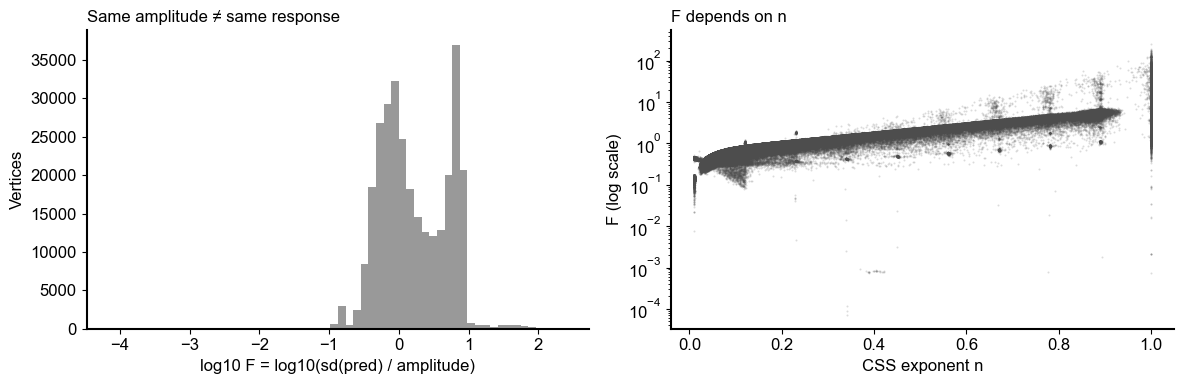

In [7]:
d = vertices[vertices.keep & (vertices.part == 'full')]
F = np.concatenate([d.sd_pred_L / d.prf_amplitude_L, d.sd_pred_R / d.prf_amplitude_R])
n = np.concatenate([d.n_L, d.n_R])
ok = np.isfinite(F) & (F > 0)
print('F = sd(pred) / amplitude: percentiles 5/25/50/75/95 = {}'.format(np.round(np.percentile(F[ok], [5, 25, 50, 75, 95]), 3)))
print('Spearman(F, n) = {:.2f}'.format(stats.spearmanr(F[ok], n[ok])[0]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(F[ok]), bins=60, color='0.6')
axes[0].set_xlabel('log10 F = log10(sd(pred) / amplitude)')
axes[0].set_ylabel('Vertices')
axes[0].set_title('Same amplitude ≠ same response', loc='left', fontsize=12)
axes[1].scatter(n[ok], F[ok], s=2, color='0.3', alpha=0.2, linewidth=0)
axes[1].set_yscale('log')
axes[1].set_xlabel('CSS exponent n')
axes[1].set_ylabel('F (log scale)')
axes[1].set_title('F depends on n', loc='left', fontsize=12)
plt.tight_layout()
plt.show()

## 1. Controls: is the measure centred on 0 and narrow?

Controls have no amblyopia, so their index should be close to 0 (small |median|) with a small spread across subjects. Their spread is the null against which patients are judged.

In [8]:
d = roi_values[(roi_values.part == 'full') & (roi_values.group == 'control')]
rows = []
for m in methods:
    for roi in rois_to_keep:
        v = d[d.roi == roi][m].dropna()
        rows.append({'method': m, 'roi': roi, 'n': len(v), 'median': v.median(), 'sd': v.std(), 'max_abs': v.abs().max()})
controls_table = pd.DataFrame(rows)
print(controls_table.pivot(index='method', columns='roi', values='sd').reindex(index=methods, columns=rois_to_keep).round(3))
print('\nControls |median| per ROI:')
print(controls_table.pivot(index='method', columns='roi', values='median').abs().reindex(index=methods, columns=rois_to_keep).round(3))

roi            V1     V2     V3     V4    V3A    V3B    LO1    LO2
method                                                            
amplitude   0.117  0.133  0.171  0.198  0.210  0.217  0.286  0.474
response    0.063  0.079  0.091  0.087  0.075  0.083  0.121  0.098
glm_own     0.063  0.079  0.091  0.087  0.076  0.083  0.117  0.099
glm_common  0.063  0.078  0.091  0.088  0.073  0.084  0.126  0.098

Controls |median| per ROI:
roi            V1     V2     V3     V4    V3A    V3B    LO1    LO2
method                                                            
amplitude   0.008  0.006  0.021  0.028  0.011  0.028  0.038  0.214
response    0.007  0.032  0.037  0.046  0.005  0.053  0.012  0.095
glm_own     0.007  0.032  0.037  0.046  0.006  0.053  0.012  0.096
glm_common  0.005  0.032  0.036  0.039  0.008  0.049  0.012  0.099


## 2. Reliability: half A (bars) vs half B (rings/wedges)

The GLM β of each eye is re-estimated on half A (bar runs) and half B (rings/wedges runs), with the pRF shape of the full fit. Stimulus-dependent factors cancel in the index (both eyes saw the same stimuli), so a good measure gives the same values in both halves. `amplitude` and `response` have no half values (single fit), so their rows stay empty.

- **across subjects**: correlation of the ROI values (signed) between halves - are differences between subjects real?
- **vertex-wise**: median across subjects of the within-subject correlation of the vertex index between halves - are the maps reproducible?

Across-subject r (ROI values, half A vs half B):
roi           V1    V2    V3    V4   V3A   V3B   LO1   LO2
method                                                    
amplitude    NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
response     NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
glm_own     0.10  0.24  0.24  0.21 -0.05  0.10 -0.15 -0.30
glm_common  0.08  0.24  0.22  0.24 -0.06  0.16 -0.01 -0.31

Vertex-wise r (median across subjects):
roi           V1    V2    V3    V4   V3A   V3B   LO1   LO2
method                                                    
amplitude    NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
response     NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
glm_own     0.21  0.25  0.12 -0.01  0.18 -0.25  0.09  0.03
glm_common  0.22  0.25  0.24  0.06  0.17 -0.07  0.19  0.06


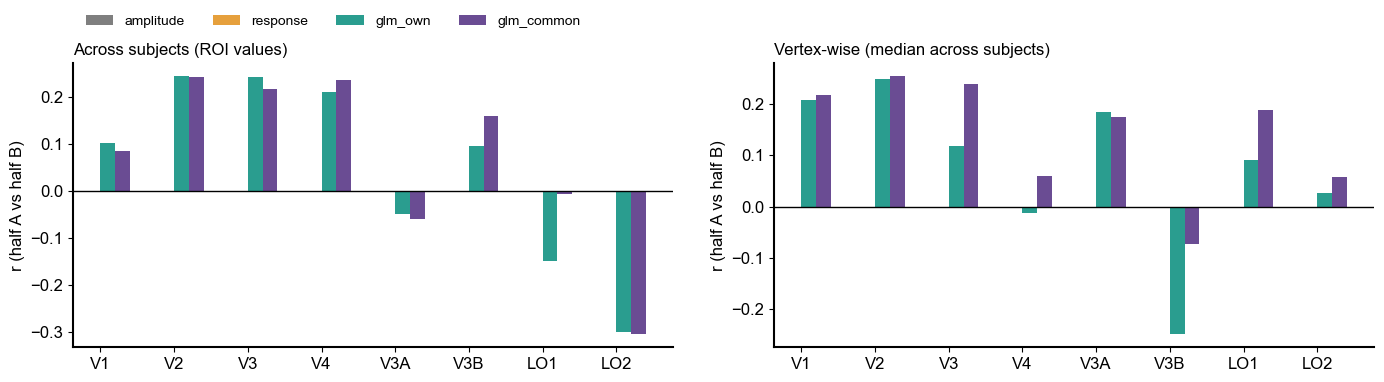

In [9]:
rows = []
wide = roi_values[roi_values.part.isin(['A', 'B'])].pivot_table(index=['subject', 'roi'], columns='part', values=methods)
for m in methods:
    for roi in rois_to_keep:
        w = wide.xs(roi, level='roi')[m].dropna() if m in wide.columns.get_level_values(0) else pd.DataFrame(columns=['A', 'B'])
        rows.append({'method': m, 'roi': roi, 'n': len(w), 'r_subjects': np.corrcoef(w.A, w.B)[0, 1] if len(w) > 2 else np.nan})
rel_subjects = pd.DataFrame(rows)

rows = []
for (subject, roi), d in vertices[vertices.keep].groupby(['subject', 'roi']):
    a, b = d[d.part == 'A'].set_index('vertex'), d[d.part == 'B'].set_index('vertex')
    for m in methods:
        va, vb = a['od_{}'.format(m)].align(b['od_{}'.format(m)], join='inner')
        ok = np.isfinite(va) & np.isfinite(vb)
        if ok.sum() > 10:
            rows.append({'subject': subject, 'roi': roi, 'method': m, 'r_vertex': np.corrcoef(va[ok], vb[ok])[0, 1]})
rel_vertex = pd.DataFrame(rows, columns=['subject', 'roi', 'method', 'r_vertex']).groupby(['method', 'roi']).r_vertex.median().reset_index()

print('Across-subject r (ROI values, half A vs half B):')
print(rel_subjects.pivot(index='method', columns='roi', values='r_subjects').reindex(index=methods, columns=rois_to_keep).round(2))
print('\nVertex-wise r (median across subjects):')
print(rel_vertex.pivot(index='method', columns='roi', values='r_vertex').reindex(index=methods, columns=rois_to_keep).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
width = 0.8 / len(methods)
for ax, table, col, title in [(axes[0], rel_subjects, 'r_subjects', 'Across subjects (ROI values)'),
                              (axes[1], rel_vertex, 'r_vertex', 'Vertex-wise (median across subjects)')]:
    for i, m in enumerate(methods):
        t = table[table.method == m].set_index('roi').reindex(rois_to_keep)
        ax.bar(np.arange(len(rois_to_keep)) + (i - 1.5) * width, t[col], width, color=method_colors[m], label=m)
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(range(len(rois_to_keep)))
    ax.set_xticklabels(rois_to_keep)
    ax.set_ylabel('r (half A vs half B)')
    ax.set_title(title, loc='left', fontsize=12)
axes[0].legend(frameon=False, ncol=4, fontsize=10, loc='lower left', bbox_to_anchor=(0, 1.08))
plt.tight_layout()
plt.show()

## 3. pRF shape confound

`glm_common` uses the same regressor for both eyes, so it cannot depend on pRF shape differences between the eyes. For each other measure: vertex-wise Spearman correlation between (measure − `glm_common`) and `log_F_ratio`, per subject and ROI (full fits). A strong (negative) correlation means the measure partly reflects pRF shape, not response gain. Expected: strong for `amplitude`.

Spearman (measure − glm_common) vs log_F_ratio, median across subjects:
roi          V1    V2    V3    V4  V3A   V3B   LO1   LO2
method                                                  
amplitude -1.00 -1.00 -1.00 -1.00 -1.0 -1.00 -1.00 -0.99
glm_own   -0.23 -0.29 -0.23 -0.25 -0.3 -0.38 -0.40 -0.35
response  -0.20 -0.26 -0.20 -0.15 -0.2 -0.28 -0.34 -0.29


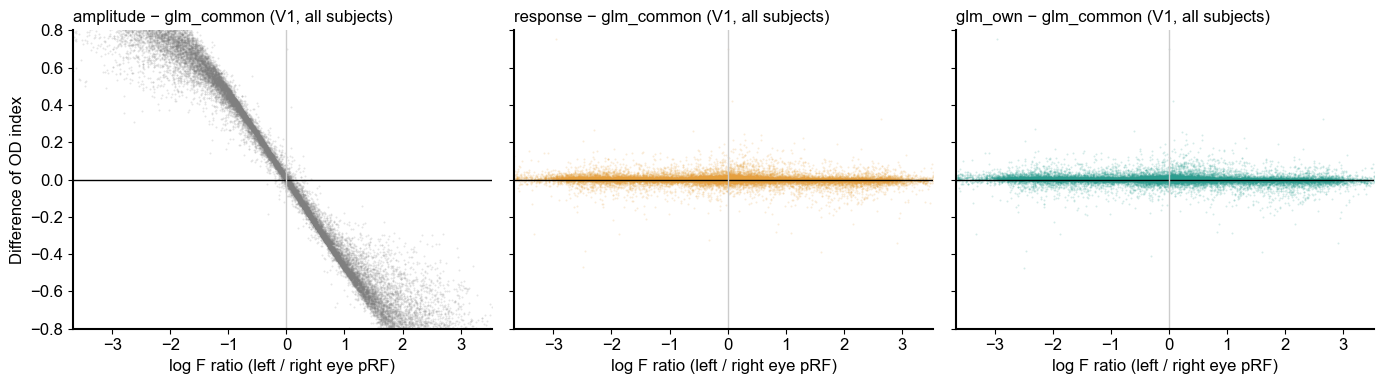

In [10]:
rows = []
for (subject, roi), d in vertices[vertices.keep & (vertices.part == 'full')].groupby(['subject', 'roi']):
    lf = d.log_F_ratio.values
    for m in ['amplitude', 'response', 'glm_own']:
        dev = (d['od_{}'.format(m)] - d.od_glm_common).values
        ok = np.isfinite(dev) & np.isfinite(lf)
        if ok.sum() > 10:
            rows.append({'subject': subject, 'roi': roi, 'method': m, 'rho': stats.spearmanr(lf[ok], dev[ok])[0],
                         'abs_dev': np.median(np.abs(dev[ok]))})
shape_dep = pd.DataFrame(rows)
print('Spearman (measure − glm_common) vs log_F_ratio, median across subjects:')
print(shape_dep.groupby(['method', 'roi']).rho.median().unstack().reindex(columns=rois_to_keep).round(2))

# Example: pooled V1 vertices of all subjects
d = vertices[vertices.keep & (vertices.part == 'full') & (vertices.roi == 'V1')]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, ['amplitude', 'response', 'glm_own']):
    dev = d['od_{}'.format(m)] - d.od_glm_common
    ok = np.isfinite(dev) & np.isfinite(d.log_F_ratio)
    ax.scatter(d.log_F_ratio[ok], dev[ok], s=2, color=method_colors[m], alpha=0.2, linewidth=0)
    ax.axhline(0, color='black', lw=1)
    ax.axvline(0, color='0.8', lw=1)
    ax.set_xlim(np.nanpercentile(d.log_F_ratio[ok], [1, 99]))
    ax.set_ylim(-0.8, 0.8)
    ax.set_xlabel('log F ratio (left / right eye pRF)')
    ax.set_title('{} − glm_common (V1, all subjects)'.format(m), loc='left', fontsize=12)
axes[0].set_ylabel('Difference of OD index')
plt.tight_layout()
plt.show()

## 4. Sensitivity: patients (fellow − amblyopic) vs controls (right − left)

Per ROI and measure: one dot per subject (full data). Printed: medians, control SD, standardized separation d = (mean patients − mean controls) / pooled SD, Wilcoxon (patients vs 0) and Mann-Whitney (patients vs controls) p-values, uncorrected - for comparing measures, not for reporting.

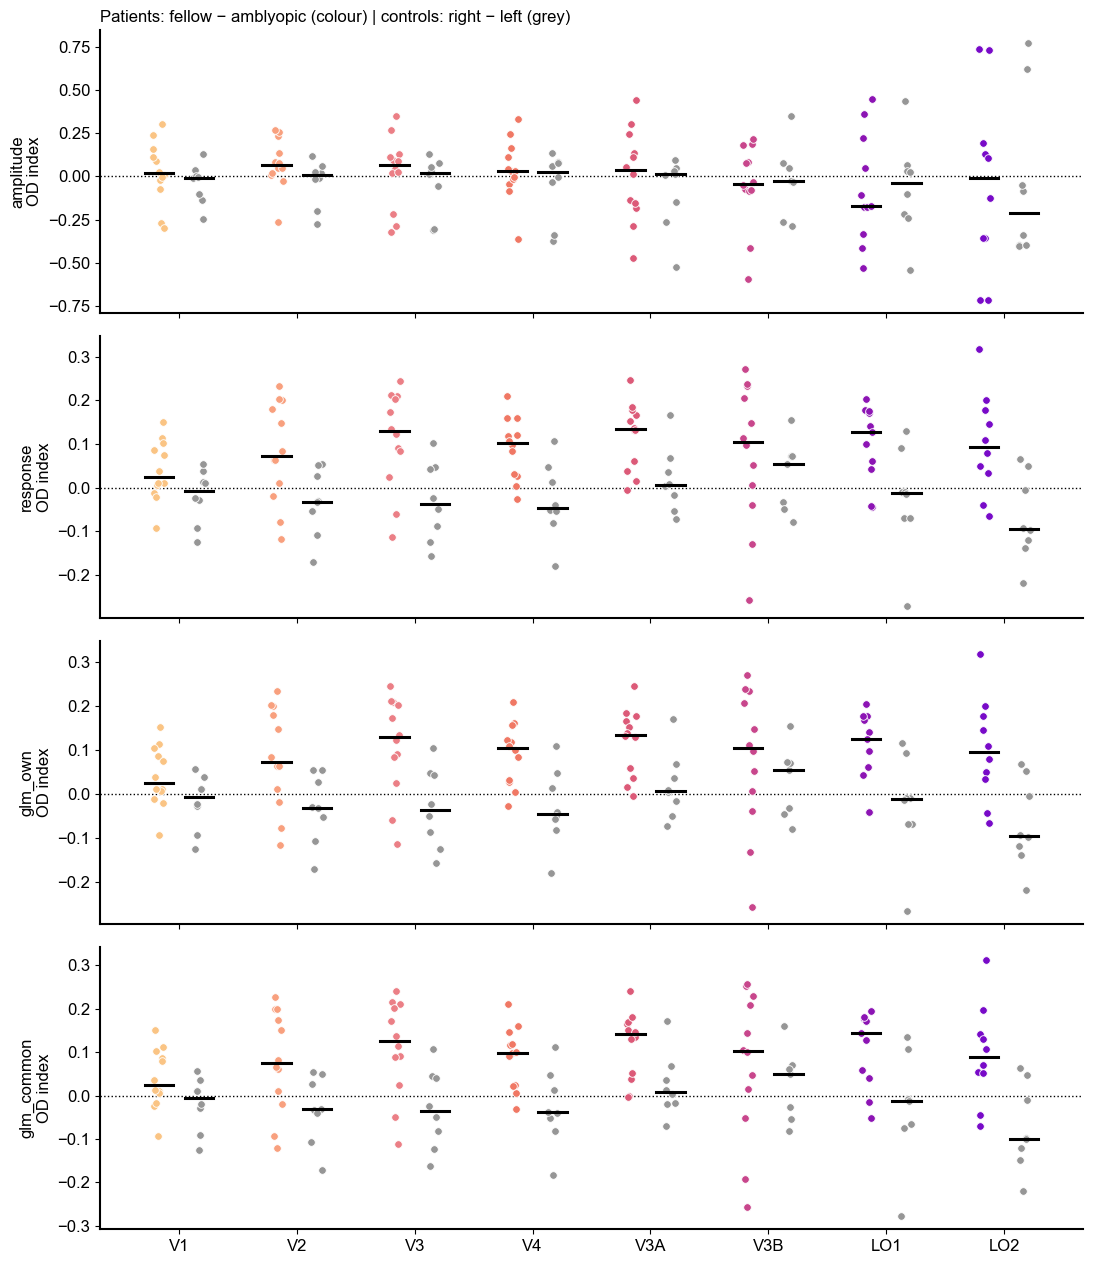

    method roi  median_patients  median_controls  sd_controls      d  p_patients_vs_0  p_patients_vs_controls
 amplitude  V1            0.018           -0.008        0.117  0.405            0.519                   0.343
 amplitude  V2            0.064            0.006        0.133  0.776            0.052                   0.098
 amplitude  V3            0.064            0.021        0.171  0.365            0.470                   0.305
 amplitude  V4            0.033            0.028        0.198  0.476            0.380                   0.678
 amplitude V3A            0.035            0.011        0.210  0.405            0.970                   0.384
 amplitude V3B           -0.041           -0.028        0.217 -0.120            0.910                   0.967
 amplitude LO1           -0.170           -0.038        0.286 -0.023            0.520                   0.968
 amplitude LO2           -0.010           -0.214        0.474 -0.004            1.000                   0.897
  response

In [11]:
d = roi_values[roi_values.part == 'full']
rows = []
fig, axes = plt.subplots(len(methods), 1, figsize=(11, 3.2 * len(methods)), sharex=True)
rng = np.random.default_rng(0)
for ax, m in zip(axes, methods):
    for i, roi in enumerate(rois_to_keep):
        vp = d[(d.group == 'patient') & (d.roi == roi)][m].dropna().values
        vc = d[(d.group == 'control') & (d.roi == roi)][m].dropna().values
        for v, dx, color in [(vp, -0.17, roi_colors[roi]), (vc, 0.17, color_ctrl)]:
            ax.scatter(i + dx + rng.uniform(-0.05, 0.05, v.size), v, s=30, color=color, edgecolor='white', linewidth=0.6, zorder=3)
            ax.plot([i + dx - 0.12, i + dx + 0.12], [np.median(v)] * 2, color='black', lw=2.2, zorder=4)
        pooled_sd = np.sqrt(((vp.size - 1) * vp.var(ddof=1) + (vc.size - 1) * vc.var(ddof=1)) / (vp.size + vc.size - 2))
        rows.append({'method': m, 'roi': roi, 'median_patients': np.median(vp), 'median_controls': np.median(vc),
                     'sd_controls': vc.std(ddof=1), 'd': (vp.mean() - vc.mean()) / pooled_sd,
                     'p_patients_vs_0': stats.wilcoxon(vp)[1], 'p_patients_vs_controls': stats.mannwhitneyu(vp, vc)[1]})
    ax.axhline(0, color='black', lw=1, ls=':')
    ax.set_ylabel('{}\nOD index'.format(m))
axes[-1].set_xticks(range(len(rois_to_keep)))
axes[-1].set_xticklabels(rois_to_keep)
axes[0].set_title('Patients: fellow − amblyopic (colour) | controls: right − left (grey)', loc='left', fontsize=12)
plt.tight_layout()
plt.show()
sensitivity = pd.DataFrame(rows)
print(sensitivity.round(3).to_string(index=False))

## 5. Clinical validity: does OD follow the depth of amblyopia?

Patients only (n = 12, so only large effects will show): Spearman correlation between the fellow − amblyopic index and the logMAR acuity of the amblyopic eye (higher logMAR = deeper amblyopia). A meaningful OD measure should correlate positively. Full data and, for the GLM measures, each half separately (a real relation should appear in both).

    method roi  rho_full  rho_A  rho_B
 amplitude  V1      0.09    NaN    NaN
 amplitude  V2      0.08    NaN    NaN
 amplitude  V3     -0.11    NaN    NaN
 amplitude  V4     -0.04    NaN    NaN
 amplitude V3A     -0.16    NaN    NaN
 amplitude V3B      0.16    NaN    NaN
 amplitude LO1     -0.19    NaN    NaN
 amplitude LO2     -0.16    NaN    NaN
  response  V1      0.30    NaN    NaN
  response  V2      0.43    NaN    NaN
  response  V3      0.30    NaN    NaN
  response  V4      0.23    NaN    NaN
  response V3A      0.15    NaN    NaN
  response V3B      0.42    NaN    NaN
  response LO1     -0.15    NaN    NaN
  response LO2     -0.27    NaN    NaN
   glm_own  V1      0.30  -0.06   0.47
   glm_own  V2      0.41   0.16   0.31
   glm_own  V3      0.30  -0.04   0.29
   glm_own  V4      0.23  -0.20   0.34
   glm_own V3A      0.15   0.01   0.38
   glm_own V3B      0.42   0.35   0.28
   glm_own LO1     -0.11  -0.19   0.29
   glm_own LO2     -0.27  -0.18   0.07
glm_common  V1      0.32 

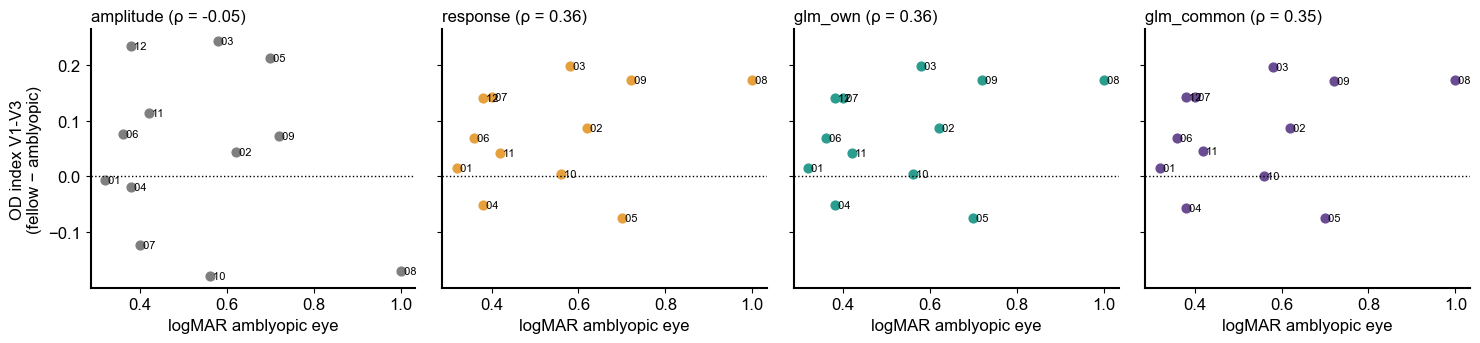

In [12]:
rows = []
for m in methods:
    for roi in rois_to_keep:
        row = {'method': m, 'roi': roi}
        for part in ['full', 'A', 'B']:
            d = roi_values[(roi_values.part == part) & (roi_values.group == 'patient') & (roi_values.roi == roi)]
            acuity = d.subject.map(log_mar)
            ok = np.isfinite(d[m]) & np.isfinite(acuity)
            row['rho_{}'.format(part)] = stats.spearmanr(d[m][ok], acuity[ok])[0]
        rows.append(row)
clinical = pd.DataFrame(rows)
print(clinical.round(2).to_string(index=False))

# V1-V3 average, full data
fig, axes = plt.subplots(1, len(methods), figsize=(15, 3.6), sharey=True)
for ax, m in zip(axes, methods):
    d = roi_values[(roi_values.part == 'full') & (roi_values.group == 'patient') & roi_values.roi.isin(['V1', 'V2', 'V3'])]
    v = d.groupby('subject')[m].mean()
    acuity = v.index.map(log_mar)
    ax.scatter(acuity, v, s=40, color=method_colors[m])
    for s, a, val in zip(v.index, acuity, v):
        ax.text(a, val, ' ' + s[4:], fontsize=8, va='center')
    ax.axhline(0, color='black', lw=1, ls=':')
    ax.set_xlabel('logMAR amblyopic eye')
    ax.set_title('{} (ρ = {:.2f})'.format(m, stats.spearmanr(acuity, v, nan_policy='omit')[0]), loc='left', fontsize=12)
axes[0].set_ylabel('OD index V1-V3\n(fellow − amblyopic)')
plt.tight_layout()
plt.show()

## 6. Summary and decision

One line per measure, averaged over ROIs:

| column | criterion | better |
|---|---|---|
| `controls_sd` | spread of the control values (section 1) | lower |
| `controls_abs_median` | bias in controls | lower |
| `r_subjects` | across-subject split-half reliability (2) | higher |
| `r_vertex` | map reliability (2) | higher |
| `shape_rho` | dependence on pRF shape differences (3) | closer to 0 |
| `d_patients_controls` | separation of patients from controls (4) | higher |
| `rho_acuity` | correlation with amblyopia depth (5) | higher |

**How to decide whether OD makes sense in these data:** a usable measure should (1) be centred on 0 in controls, (2) be reliable across independent fits (r clearly > 0, ideally > 0.5), (3) not follow pRF shape differences, and only then (4) separate patients from controls and (5) follow amblyopia depth. If no measure passes (2), subject-level OD is not interpretable with these data, whatever the group result. One limit no measure can remove: the two eyes are recorded in different runs, so a global change of response gain between the runs of each eye adds to every measure; the control spread is the estimate of that noise.

In [13]:
summary = pd.DataFrame(index=methods)
summary['controls_sd'] = controls_table.groupby('method').sd.mean()
summary['controls_abs_median'] = controls_table.assign(a=controls_table['median'].abs()).groupby('method').a.mean()
summary['r_subjects'] = rel_subjects.groupby('method').r_subjects.mean()
summary['r_vertex'] = rel_vertex.groupby('method').r_vertex.mean()
summary['shape_rho'] = shape_dep.groupby('method').rho.median()
summary['d_patients_controls'] = sensitivity.groupby('method').d.mean()
summary['rho_acuity'] = clinical.groupby('method').rho_full.mean()
print(summary.round(3).to_string())

            controls_sd  controls_abs_median  r_subjects  r_vertex  shape_rho  d_patients_controls  rho_acuity
amplitude         0.226                0.044         NaN       NaN     -0.996                0.285      -0.040
response          0.087                0.036         NaN       NaN     -0.226                1.181       0.178
glm_own           0.087                0.036       0.050     0.077     -0.282                1.180       0.179
glm_common        0.088                0.035       0.071     0.140        NaN                1.154       0.167
